# Where Gemma picks BFS or DFS: finding the fork token (claim S, stage S4)

**Artifact:** `art_zNyBP6zieI5u`, an experiment on `google/gemma-3-4b-it` (bf16).

**Setup.** Ask Gemma for one grid path-finding function (task T1). About 70% of its programs use depth-first search (DFS) and about 30% use breadth-first search (BFS). The experiment asks *where* in the generation that choice is made. It then asks whether the model's own sparse autoencoders (Gemma Scope 2) read and steer the choice better than simple baselines (difference in means, raw residual, random features, prompting).

**The full pipeline** is `method.py`, with one function per stage. Most stages need the gated model on a 16 GB GPU; the full run took about 4 GPU-hours:

| Stage | What it does | Runs on |
|---|---|---|
| `s0`, `gen1` | input checks, CRN unit tests, natural splits (N = 200 per task), contrast prompts | GPU |
| **`fork` (S4)** | **prefix resampling: 3,712 continuations, change points, the fork token** | **GPU sampling, then the CPU analysis replayed here** |
| `tfgate`, `variants`, `select` | teacher-forced states, SAE quality gate, 120 prompt variants, feature selection | GPU |
| `clamps`, `das`, `attrib` | steering cells (SAE clamps vs DiM, random and isotropic edits), DAS, attribution | GPU |
| `label`, `analysis`, `outputs` | labelling, statistics, figures, output JSON | CPU |

**What this notebook runs.** The CPU half of `stage_fork` in `method.py`, nearly verbatim, with the helpers it imports from `src/fork.py` and `src/cfg.py`. The original sampled the continuations from Gemma on the GPU. Here the model's **real** continuations are loaded from `mini_demo_data.json`, a 95-cell subset of the artifact's `fork_resampling` dataset:

- **Base paths:** 5 natural samples, 3 BFS and 2 DFS, one per prompt template W1-W5.
- **Coarse cells:** each path cut at the 16 prefix lengths t = 0, 4, ..., 60, with 8 resampled continuations each.
- **Refinement cells:** for the 3 BFS paths, a cut at every single token around their change point, with 16 continuations each.

**What to look for.**
1. Each BFS base path keeps a low BFS share until about t = 32. Then the share jumps to about 1. A binomial change-point test with a permutation null flags the jump.
2. The single-token refinement pins the jump to **one token at response index about 32**. That index sits right after the opening that almost every program shares: ```` ```python ````, then `def solve(grid, start, goal):`, `rows = len(grid)`, `cols = len(grid[0])` and an indent.
3. The token at that position decides the algorithm: `visited` leads to DFS, while a newline, `if` or `queue` leads to BFS. The code itself reveals the algorithm only about 140 tokens later.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
# ---- original import block of method.py (ROOT / sys.path / `from cfg import ...` are replaced by the cells below)
from __future__ import annotations

import argparse
import gc
import json
import os
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- imports of src/fork.py and src/cfg.py, whose helpers are copied into this notebook
import hashlib
import itertools
import math
import re
from collections import Counter

import numpy as np

# ---- notebook additions: a namespace standing in for `import fork as F`, tables and figures
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-6/experiment-31/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# until this demo's files are pushed, GITHUB_DATA_URL can still serve a stale copy from an earlier build of the demo
# (another layout): use the local file then
if data.get("datasets", [{}])[0].get("dataset") != "fork_resampling" or "selection" not in data.get("metadata", {}):
    print("GitHub copy has another layout (stale build), using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
meta = data["metadata"]                       # base paths, token decode table, stored results for comparison
examples = data["datasets"][0]["examples"]    # one (base path, prefix length t) resampling cell per example
print(data["datasets"][0]["dataset"], "-", len(examples), "examples:", meta["selection"])
print("model:", meta["model"]["id"], "@", meta["model"]["revision"][:12], "|", meta["model"]["decoding"])
ex = examples[8]
print("\nexample cell:", ex["input"][:90], "...")
print({k: v for k, v in ex.items() if k not in ("input", "metadata_continuations")})
print("first continuation (prefix + resampled code):\n" + ex["metadata_continuations"][0]["text"][:400])

GitHub copy has another layout (stale build), using local mini_demo_data.json
fork_resampling - 95 examples: {'bfs_base_paths': ['s3|T1|W2|twin|4', 's3|T1|W3|twin|0', 's3|T1|W4|twin|3'], 'dfs_base_paths': ['s3|T1|W1|twin|0', 's3|T1|W5|twin|1'], 'n_examples': 95, 'n_coarse': 80, 'n_refine': 15}
model: google/gemma-3-4b-it @ 093f9f388b31 | temperature 1.0, top-p 1.0, no top-k, CRN uniforms

example cell: [W2 twin prompt] + response prefix of 32 tokens: [2717, 6719, 107, 2063, 8974, 236769, 854 ...
{'output': 'bfs', 'predict_p_bfs_continuations': '0.1250', 'predict_own_class_share': '0.1250', 'metadata_base_row': 's3|T1|W2|twin|4', 'metadata_t': 32, 'metadata_n_continuations': 8, 'metadata_path_fork_t': 36, 'metadata_change_point_p': 0.000999000999000999, 'metadata_tag': 'coarse', 'metadata_template': 'W2'}
first continuation (prefix + resampled code):
```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(r

## Configuration

These are all the tunable parameters of the S4 analysis: the `src/cfg.py` constants and the `method.py` command-line defaults (original values in the comments).

- `FORK_PERM` is the only real compute knob. Each change-point test refits the segmentation on `FORK_PERM` shuffled copies of a path. With fewer than 20 permutations, no p-value can fall below 0.05, so no fork can be declared.
- `N_PATHS_PER_CLASS` caps how many base paths per class `pick()` takes. The original used 12 BFS and 12 DFS paths; the demo data holds 3 BFS and 2 DFS.
- The continuation counts are fixed by the data: 8 per coarse cell and 16 per refinement cell.

In [5]:
# ---- S4 fork resampling (src/cfg.py)
FORK_POSITIONS = tuple(range(0, 61, 4))    # coarse scan t in {0, 4, ..., 60}                  (original: same)
FORK_CONT = 8                              # continuations per (path, t)                       (original: 8; fixed by the data)
FORK_REFINE_CONT = 16                      # continuations per refinement cell                 (original: 16; fixed by the data)
FORK_MAX_NEW = 320                         # partial-code labeller horizon (tokens)            (original: 320)
FORK_RISE = 0.4                            # min rise of the own-class share at a fork          (original: 0.4)
FORK_PERM = 1000                  # permutations of the change-point null             (original: 1000)
TOKEN_SET_HI = 0.8                         # B = fork tokens with P(BFS | tok) >= 0.8           (original: 0.8)
TOKEN_SET_LO = 0.2                         # D = fork tokens with P(BFS | tok) <= 0.2           (original: 0.2)
# ---- method.py stage_fork / CLI
N_PATHS_PER_CLASS = 12            # base paths per class, pick(cls, n_want)           (original: 12; demo data: 3 BFS + 2 DFS)
REFINE_PATHS = 8                  # --refine-paths: forked paths refined per token    (original: 8)

## Shared helpers from `src/cfg.py`

These are copied verbatim:
- the prompt-template ids W1-W5, which `pick()` cycles through;
- `stable_seed`, which keys every random stream in the artifact (sampling uniforms, the permutation nulls);
- the Wilson interval;
- the stdout part of `setup_logging` (the original also writes a log file).

In [6]:
# ---- src/cfg.py (verbatim excerpts)
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")   -- no log files in this notebook


setup_logging("method_fork")   # main(): setup_logging(f"method_{args.stage}")

## The partial-code labeller (`src/fork.py`)

A continuation stops as soon as its algorithm is decided (at most 320 tokens), so it is usually an unfinished program. The partial labeller therefore classifies a program *prefix* by the first decisive piece of lexical evidence:

- **BFS:** a FIFO pop (`.popleft()`, `.pop(0)`, `queue.Queue`).
- **DFS:** a stack pop, or a recursive self-call inside a nested function.
- **other:** a heap (`heappush`, `PriorityQueue`).

On the artifact's 200 natural samples it agreed with the full labeller 200/200 times (unit test U8).

In [7]:
# ---- src/fork.py: the partial-code labeller (verbatim)
BFS_RE = re.compile(r"\.popleft\s*\(|\.pop\s*\(\s*0\s*\)|\.get\s*\(\s*\)\s*$|\bqueue\.Queue\s*\(|\bSimpleQueue\s*\(", re.M)
STACK_RE = re.compile(r"\b(\w*stack\w*)\s*\.\s*pop\s*\(\s*\)|LifoQueue\s*\(", re.I)
HEAP_RE = re.compile(r"\bheappush\s*\(|\bheappop\s*\(|\bPriorityQueue\s*\(")
DEF_RE = re.compile(r"^([ \t]*)def\s+(\w+)\s*\(", re.M)


def _code(text: str) -> str:
    i = text.find("```")
    if i >= 0:
        j = text.find("\n", i)
        text = text[j + 1:] if j >= 0 else ""
    k = text.find("```")
    return text[:k] if k >= 0 else text


def recursion_pos(code: str) -> int | None:
    """Char position of the first self-call inside the body of a nested def (partial text allowed)."""
    best = None
    for m in DEF_RE.finditer(code):
        ind = len(m.group(1).expandtabs(4))
        name = m.group(2)
        if name == "solve" and ind == 0:
            continue
        body_start = code.find("\n", m.end())
        if body_start < 0:
            continue
        pos = body_start + 1
        for line in code[body_start + 1:].split("\n"):
            stripped = line.strip()
            if stripped:
                li = len(line) - len(line.lstrip())
                if li <= ind:
                    break
                mm = re.search(r"(?<![\w.])" + re.escape(name) + r"\s*\(", line)
                if mm and not stripped.startswith("def "):
                    cand = pos + mm.start()
                    best = cand if best is None else min(best, cand)
                    break
            pos += len(line) + 1
    return best


def evidence(text: str) -> dict[str, int | None]:
    code = _code(text)
    out: dict[str, int | None] = {}
    m = BFS_RE.search(code)
    out["bfs"] = m.start() if m else None
    m = STACK_RE.search(code)
    st = m.start() if m else None
    rc = recursion_pos(code)
    out["dfs"] = min([x for x in (st, rc) if x is not None], default=None)
    m = HEAP_RE.search(code)
    out["other"] = m.start() if m else None
    return out


def partial_label(text: str) -> str | None:
    """'bfs' | 'dfs' | 'other' at the first decisive evidence in the program prefix; None while undecided."""
    ev = evidence(text)
    cands = [(v, k) for k, v in ev.items() if v is not None]
    if not cands:
        return None
    return min(cands)[1]


def decided(text: str) -> bool:
    return partial_label(text) is not None


def map_full(label: str) -> str:
    return label if label in ("bfs", "dfs") else "other"

## Binomial change points with a permutation null (`src/fork.py`)

For one base path, `k[i]` of `n[i]` continuations keep the path's own class at prefix length `t[i]`.
- `best_segmentation` tries every split into 2 or 3 segments with a constant binomial rate. It returns the largest log-likelihood gain, with a BIC-style penalty on a second change point.
- `change_points` compares that gain with the gains on `n_perm` random reorderings of the positions.

A small p-value means the own-class share changes *at a specific prefix length*, rather than drifting smoothly.

In [8]:
# ---- src/fork.py: change points (verbatim)
def best_segmentation(k: np.ndarray, n: np.ndarray, max_cp: int = 2) -> tuple[float, list[int]]:
    """Exhaustive binomial segmentation with up to max_cp change points (prefix sums); returns (log-likelihood gain
    over no change, minus a BIC-style 1.5 log N penalty per change point beyond the first, cps); cp = index i means a
    change between positions i-1 and i."""
    T = len(k)
    ck = [0.0]
    cn = [0.0]
    for a, b in zip(k, n):
        ck.append(ck[-1] + float(a))
        cn.append(cn[-1] + float(b))

    def ll(i: int, j: int) -> float:
        K, N = ck[j] - ck[i], cn[j] - cn[i]
        if N <= 0 or K <= 0 or K >= N:
            return 0.0
        p = K / N
        return K * math.log(p) + (N - K) * math.log(1 - p)
    base = ll(0, T)
    pen = 1.5 * math.log(max(cn[-1], 2.0))
    best = (0.0, [])
    for i in range(1, T):
        g = ll(0, i) + ll(i, T) - base
        if g > best[0] + 1e-12:
            best = (g, [i])
    if max_cp >= 2:
        for i in range(1, T - 1):
            li = ll(0, i)
            for j in range(i + 1, T):
                g = li + ll(i, j) + ll(j, T) - base - pen
                if g > best[0] + 1e-12:
                    best = (g, [i, j])
    return best


def change_points(k: list[int], n: list[int], n_perm: int = 1000, seed: int = 0) -> dict[str, Any]:
    k_a, n_a = np.asarray(k, float), np.asarray(n, float)
    gain, cps = best_segmentation(k_a, n_a)
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        o = rng.permutation(len(k_a))
        null.append(best_segmentation(k_a[o], n_a[o])[0])
    p = (1 + sum(g >= gain for g in null)) / (1 + n_perm)
    segs = []
    b = [0, *cps, len(k_a)]
    for i in range(len(b) - 1):
        kk, nn = k_a[b[i]:b[i + 1]].sum(), n_a[b[i]:b[i + 1]].sum()
        segs.append({"start_idx": b[i], "end_idx": b[i + 1], "p": float(kk / nn) if nn else None})
    return {"gain": gain, "cps": cps, "p_value": p, "segments": segs}

## Prefix bookkeeping (`src/fork.py`)

These helpers compute:
- the longest common prefix of two programs;
- the identical-prefix share within a template;
- the canonical prefix `c*`, the most common first-t tokens;
- the token table: P(BFS) for every token that follows `c*`.

The last line builds a namespace `F`, so the `method.py` code below can call `F.partial_label(...)` and the other helpers unchanged.

In [9]:
# ---- src/fork.py: prefixes (verbatim)
def lcp(a: list[int], b: list[int]) -> int:
    n = 0
    for x, y in zip(a, b):
        if x != y:
            break
        n += 1
    return n


def identical_prefix_share(ids_by_template: dict[str, list[list[int]]], t: int) -> dict[str, float]:
    out = {}
    for w, L in ids_by_template.items():
        pairs = list(itertools.combinations(range(len(L)), 2))
        same = sum(1 for i, j in pairs if len(L[i]) >= t and len(L[j]) >= t and L[i][:t] == L[j][:t])
        out[w] = same / len(pairs) if pairs else float("nan")
    return out


def canonical_prefix(ids: list[list[int]], t: int) -> tuple[list[int], int]:
    c = Counter(tuple(x[:t]) for x in ids if len(x) >= t)
    pref, cnt = c.most_common(1)[0]
    return list(pref), cnt


def token_table(rows: list[dict[str, Any]], cstar: list[int], min_n: int = 3) -> dict[int, dict[str, Any]]:
    """rows: {ids (response), cls ('bfs'|'dfs'|'other')}; tokens right after c* among rows whose prefix is c*."""
    t = len(cstar)
    by: dict[int, list[str]] = {}
    for r in rows:
        ids = r["ids"]
        if len(ids) > t and ids[:t] == cstar:
            by.setdefault(int(ids[t]), []).append(r["cls"])
    out = {}
    for tok, cl in by.items():
        n_bd = sum(c in ("bfs", "dfs") for c in cl)
        out[tok] = {"n": len(cl), "n_bfs": sum(c == "bfs" for c in cl), "n_dfs": sum(c == "dfs" for c in cl),
                    "p_bfs": (sum(c == "bfs" for c in cl) / n_bd) if n_bd else None, "pooled": len(cl) < min_n}
    return out


# stands in for `import fork as F` in method.py, so the stage code below keeps its F.<helper> calls
F = SimpleNamespace(partial_label=partial_label, decided=decided, map_full=map_full, change_points=change_points,
                    lcp=lcp, identical_prefix_share=identical_prefix_share, canonical_prefix=canonical_prefix,
                    token_table=token_table)

## Inputs: natural samples, tokenizer and `method.py` helpers

The original reads its inputs from three sources. This notebook replaces each one:

- **Natural samples.** `load_labelled("raw_s3.jsonl", "T1")` read all 200 natural T1 samples with their labels. The demo data holds the 5 samples used as base paths.
- **Tokenizer.** `run.tok` was the Gemma tokenizer, which is gated. `VocabTokenizer` decodes from a table of the 115 token ids involved. The table was made with the real tokenizer at the pinned revision and checked against it in `scripts/make_mini_demo_data.py`.
- **Helpers.** `response_ids` and `identifying_index` are copied from `method.py`.

In [10]:
# ---- method.py helpers (verbatim; the `import fork as F` line inside identifying_index is covered by F above)
def response_ids(r: dict[str, Any]) -> list[int]:
    """generated ids without the trailing stop token."""
    ids = list(r["token_ids"])
    while ids and ids[-1] in (1, 106):
        ids = ids[:-1]
    return ids


def identifying_index(tok: Any, ids: list[int]) -> int | None:
    """First response-token index i such that the partial labeller is decided on ids[:i+1] (binary search)."""
    if F.partial_label(tok.decode(ids, skip_special_tokens=True)) is None:
        return None
    lo, hi = 0, len(ids) - 1
    while lo < hi:
        mid = (lo + hi) // 2
        if F.partial_label(tok.decode(ids[:mid + 1], skip_special_tokens=True)) is not None:
            hi = mid
        else:
            lo = mid + 1
    return lo


class VocabTokenizer:
    """Stand-in for run.tok (the gated Gemma tokenizer), decode() only: concatenates the stored decoded string of every
    token id. Gemma 3 decodes with Replace('▁' -> ' ') + ByteFallback + Fuse and no byte-fallback piece occurs here,
    so this equals tok.decode() on every sequence the notebook decodes (asserted when the data file was built)."""

    def __init__(self, vocab: dict[str, str]):
        self.vocab = {int(k): v for k, v in vocab.items()}

    def decode(self, ids: list[int], skip_special_tokens: bool = False) -> str:
        return "".join(self.vocab[int(i)] for i in ids)


rows = [r for r in meta["base_paths"] if r["task"] == "T1" and r["arm"] == "twin"]   # was: load_labelled("raw_s3.jsonl", "T1")
tok = VocabTokenizer(meta["vocab"])                                                     # was: run = Runner(); tok = run.tok
print(f"{len(rows)} natural T1 samples (label, passed hidden tests):")
for r in rows:
    print(f"  {r['row_id']:18s} {r['label']}  passed={r['passed']}  {len(response_ids(r))} response tokens")

5 natural T1 samples (label, passed hidden tests):
  s3|T1|W2|twin|4    bfs  passed=True  264 response tokens
  s3|T1|W3|twin|0    bfs  passed=True  242 response tokens
  s3|T1|W4|twin|3    bfs  passed=True  297 response tokens
  s3|T1|W1|twin|0    dfs  passed=True  307 response tokens
  s3|T1|W5|twin|1    dfs  passed=True  317 response tokens


## S4 step 1: U8 labeller check and the algorithm-identifying token (verbatim)

- **U8** decodes the first 320 tokens of each natural program and checks that the partial labeller gives the same class as the full labeller. The full labeller runs the program on tests and reads its AST.
- **`identifying_index`** binary-searches for the first response token at which the partial labeller is decided. That is the first token at which the *code* shows the algorithm.

In [11]:
# ---------------- U8: partial labeller vs full labels on valid attempts (first 320 tokens)
conf: dict[str, int] = {}
agree = n = 0
for r in rows:
    if not r["valid"] or r["label"] in ("invalid", "disputed"):
        continue
    pl = F.partial_label(tok.decode(response_ids(r)[:FORK_MAX_NEW], skip_special_tokens=True)) or "other"
    fl = F.map_full(r["label"])
    conf[f"{fl}->{pl}"] = conf.get(f"{fl}->{pl}", 0) + 1
    n += 1
    agree += pl == fl
u8 = {"n": n, "agreement": agree / max(n, 1), "confusion": conf, "pass": agree / max(n, 1) >= 0.95}
use_partial = u8["pass"]
logger.info(f"U8 partial labeller: {u8}")
# ---------------- identifying token per S3 sample
ident = {}
for r in rows:
    ids = response_ids(r)
    i = identifying_index(tok, ids)
    ident[r["row_id"]] = {"idx": i, "token": tok.decode([ids[i]]) if i is not None else None,
                          "cls": F.map_full(r["label"]) if r["valid"] else "invalid", "template": r["template"],
                          "label": r["label"], "passed": r["passed"]}
for r in rows:   # notebook addition: show where the code first gives the algorithm away
    i = ident[r["row_id"]]["idx"]
    shown = "never decided" if i is None else repr(tok.decode(response_ids(r)[max(0, i - 12):i + 1]))
    print(f"{r['row_id']:18s} {r['label']}: identifying token index {i} -> ...{shown}")

16:26:10|INFO   |U8 partial labeller: {'n': 5, 'agreement': 1.0, 'confusion': {'bfs->bfs': 3, 'dfs->dfs': 2}, 'pass': True}


s3|T1|W2|twin|4    bfs: identifying token index 120 -> ...'(row, col), path = q.pop(0)'
s3|T1|W3|twin|0    bfs: identifying token index 112 -> ...'(row, col), path = q.pop(0)'
s3|T1|W4|twin|3    bfs: identifying token index 161 -> ...'(row, col), path = q.pop(0)'
s3|T1|W1|twin|0    dfs: identifying token index 207 -> ...' is_valid(r, c) and find_path('
s3|T1|W5|twin|1    dfs: identifying token index 170 -> ...'\n\n        # Explore adjacent cells\n        if find_path('


## S4 step 2: base paths and the resampled continuations

`pick` is verbatim: it takes valid samples of one class, round-robin over the templates, correct programs first. Each base path was cut at every t in `FORK_POSITIONS`. On the GPU, Gemma then wrote `FORK_CONT` continuations of the T1 prompt plus the first t response tokens, each stopped once the partial labeller was decided (`stop = F.decided`).

Those continuations are loaded here from the data and labelled with the original `cls_of` rule.

In [12]:
# ---------------- base paths: 12 BFS + 12 DFS valid attempts (round-robin over templates, prefer correct)
def pick(cls: str, n_want: int = 12) -> list[dict[str, Any]]:
    cand = [r for r in rows if r["valid"] and r["label"] == cls]
    by_w: dict[str, list] = {}
    for r in sorted(cand, key=lambda r: (not r["passed"], r["template"], r["slot"])):
        by_w.setdefault(r["template"], []).append(r)
    out: list[dict[str, Any]] = []
    while len(out) < n_want and any(by_w.values()):
        for w in TEMPLATE_IDS:
            if by_w.get(w) and len(out) < n_want:
                out.append(by_w[w].pop(0))
    return out
base = pick("bfs", N_PATHS_PER_CLASS) + pick("dfs", N_PATHS_PER_CLASS)   # original: pick("bfs") + pick("dfs")
stop = F.decided if use_partial else None          # the generation stop rule (GPU only)
max_new = FORK_MAX_NEW if use_partial else 1536

# ---------------- continuations: GPU sampling in the original (run.run_multi(...) -> data/fork_cont.jsonl).
# Here every (base path, t) cell of the demo data lists its real continuations.
keep = {r["row_id"] for r in base}
cont = []
for ex in examples:
    if ex["metadata_base_row"] not in keep:
        continue
    for c in ex["metadata_continuations"]:
        cont.append({"row_id": f"{ex['metadata_tag']}|{ex['metadata_base_row']}|{ex['metadata_t']}|{c['j']}",
                     "base_row": ex["metadata_base_row"], "base_label": ex["output"], "t": ex["metadata_t"],
                     "j": c["j"], "template": ex["metadata_template"], "tag": ex["metadata_tag"],
                     "text": c["text"], "token_ids": c["token_ids_head"]})   # first 40 response ids (t <= 36 used)


def cls_of(row: dict[str, Any]) -> str:
    pl = F.partial_label(row["text"])
    return pl or "other"

for c in cont:
    c["cls"] = cls_of(c)
print("base paths:", [(r["row_id"], r["label"]) for r in base])
print(f"{len(cont)} continuations ({Counter(c['tag'] for c in cont)}), classes: {Counter(c['cls'] for c in cont)}")

base paths: [('s3|T1|W2|twin|4', 'bfs'), ('s3|T1|W3|twin|0', 'bfs'), ('s3|T1|W4|twin|3', 'bfs'), ('s3|T1|W1|twin|0', 'dfs'), ('s3|T1|W5|twin|1', 'dfs')]
880 continuations (Counter({'coarse': 640, 'refine': 240})), classes: Counter({'bfs': 460, 'dfs': 420})


## S4 step 3: U6 sanity checks

- **Full prefix.** Keeping a base path's whole program as the prefix must reproduce its label.
- **Empty prefix.** At t = 0 the resampled BFS share should match the natural BFS share of the 200 samples (61/200, with a Wilson 95% CI).

In the original run, t = 0 gave a BFS share of 0.38 (n = 192), slightly above the natural 0.305 [0.25, 0.37], so the check reported `t0_within_ci: False`. The demo's t = 0 continuations show the same small excess.

In [13]:
# ---------------- U6: full-length prefix reproduces the base label; t=0 share vs S3 marginal
u6_full = all(F.map_full(r["label"]) == (F.partial_label(r["text"]) or "other") for r in base)
t0rows = [c for c in cont if c["t"] == 0 and c.get("tag") == "coarse"]
k0 = sum(c["cls"] == "bfs" for c in t0rows)
valid = [r for r in rows if r["valid"] and r["label"] not in ("invalid", "disputed")]
# the S3 marginal needs all 200 natural samples (the demo holds 5): stored counts of results/natural_split.json
kb, n_valid = meta["s3_T1_counts"]["n_bfs"], meta["s3_T1_counts"]["n_valid"]   # was: kb = sum(...) over valid
lo, hi = wilson_ci(kb, n_valid)
u6 = {"full_prefix_reproduces_label": u6_full, "t0_bfs_share": k0 / max(len(t0rows), 1), "t0_n": len(t0rows),
      "s3_bfs_share": kb / max(n_valid, 1), "s3_ci95": [lo, hi],
      "t0_within_ci": lo <= k0 / max(len(t0rows), 1) <= hi}
print(u6)

{'full_prefix_reproduces_label': True, 't0_bfs_share': 0.425, 't0_n': 40, 's3_bfs_share': 0.305, 's3_ci95': [0.24536415630735034, 0.37198552097978366], 't0_within_ci': False}


## S4 step 4: change points per base path (verbatim)

For each path and each coarse prefix length, count how many of the 8 continuations keep the path's own class, then run the permutation-tested segmentation. A **fork** is the first change point with p < 0.05 at which the own-class share rises by at least `FORK_RISE` (0.4).

- **BFS paths** should rise sharply at about t = 32-36.
- **DFS paths** already start near the 70% DFS default, so their rise usually stays below 0.4 (11 of the 12 DFS paths in the full run).

`lcp_with_other_class_max` is the longest prefix a path shares with any natural sample of the other class. Here it is computed against the 5 demo samples; the original compared against all 200.

In [14]:
# ---------------- change points per path and pooled per class
per_path = []
for r in base:
    own = F.map_full(r["label"])
    ks, ns, ts, pb = [], [], [], []
    for t in FORK_POSITIONS:
        cs = [c for c in cont if c["base_row"] == r["row_id"] and c["t"] == t and c.get("tag") == "coarse"]
        if not cs:
            continue
        ks.append(sum(c["cls"] == own for c in cs))
        ns.append(len(cs))
        ts.append(t)
        pb.append(sum(c["cls"] == "bfs" for c in cs) / len(cs))
    cp = F.change_points(ks, ns, FORK_PERM, seed=stable_seed("cp", r["row_id"]) % 2 ** 31)
    fork_t = None
    rise = None
    for i, ci in enumerate(cp["cps"]):
        before = cp["segments"][i]["p"]
        after = cp["segments"][i + 1]["p"]
        if cp["p_value"] < 0.05 and after is not None and before is not None and after - before >= FORK_RISE:
            fork_t = ts[ci]          # first coarse position after the change (fork token in (ts[ci-1], ts[ci]])
            rise = after - before
            break
    dp = np.abs(np.diff(np.array(ks) / np.array(ns))) if len(ks) > 1 else np.array([0.0])
    per_path.append({"row_id": r["row_id"], "label": r["label"], "template": r["template"], "t": ts,
                     "k_own": ks, "n": ns, "p_bfs": pb, "cp": cp, "fork_t": fork_t, "rise": rise,
                     "argmax_dp_t": ts[int(np.argmax(dp)) + 1] if len(ts) > 1 else None,
                     "lcp_with_other_class_max": max(F.lcp(response_ids(r), response_ids(o)) for o in valid
                                                     if F.map_full(o["label"]) != F.map_full(r["label"]))})
forks = [p["fork_t"] for p in per_path if p["fork_t"] is not None]
branch = "change_point" if forks else "distributed over generation"
fork_coarse = int(np.median(forks)) if forks else int(np.median([p["argmax_dp_t"] for p in per_path
                                                                 if p["argmax_dp_t"] is not None]))
for p in per_path:   # notebook addition: one line per path
    print(f"{p['row_id']:18s} {p['label']}: own-class k/8 over t = {p['k_own']}  p = {p['cp']['p_value']:.4f}  "
          f"fork_t = {p['fork_t']}  rise = {p['rise'] if p['rise'] is None else round(p['rise'], 3)}")
print(f"branch: {branch}; coarse fork (median over forked paths): t = {fork_coarse}")

s3|T1|W2|twin|4    bfs: own-class k/8 over t = [3, 3, 4, 5, 5, 3, 4, 3, 1, 8, 7, 8, 7, 8, 8, 8]  p = 0.0010  fork_t = 36  rise = 0.534
s3|T1|W3|twin|0    bfs: own-class k/8 over t = [4, 2, 1, 0, 4, 3, 2, 2, 2, 8, 8, 8, 8, 8, 8, 8]  p = 0.0010  fork_t = 36  rise = 0.722
s3|T1|W4|twin|3    bfs: own-class k/8 over t = [6, 4, 1, 1, 3, 2, 1, 1, 6, 7, 7, 8, 8, 8, 8, 8]  p = 0.0030  fork_t = 32  rise = 0.641
s3|T1|W1|twin|0    dfs: own-class k/8 over t = [6, 7, 8, 8, 6, 6, 6, 6, 6, 8, 8, 8, 8, 8, 8, 8]  p = 0.0090  fork_t = None  rise = None
s3|T1|W5|twin|1    dfs: own-class k/8 over t = [6, 5, 6, 4, 5, 6, 7, 6, 5, 8, 8, 8, 8, 8, 8, 8]  p = 0.0010  fork_t = None  rise = None
branch: change_point; coarse fork (median over forked paths): t = 36


## S4 step 5: single-token refinement (verbatim, minus the generation call)

For the first `REFINE_PATHS` forked paths, the original resampled 16 continuations at *every* prefix length in [fork_t - 4, fork_t]. The largest jump in the own-class share between neighbouring lengths marks the token that commits the plan: `fork_token = ids[fork_len - 1]`.

In [15]:
# ---------------- refinement at single-token resolution: every token in [fork-4, fork], 16 continuations
ref_paths = [p for p in per_path if p["fork_t"] is not None][:REFINE_PATHS]   # [:args.refine_paths]
by_id = {r["row_id"]: r for r in base}
# (GPU in the original: ref_items -> run.run_multi(...); the refinement continuations are already in `cont`)
refined = []
for p in ref_paths:
    r = by_id[p["row_id"]]
    ids = response_ids(r)
    own = F.map_full(r["label"])
    ser = []
    for t in range(max(0, p["fork_t"] - 4), p["fork_t"] + 1):
        cs = [c for c in cont if c["base_row"] == r["row_id"] and c["t"] == t and c.get("tag") == "refine"]
        if cs:
            ser.append({"t": t, "n": len(cs), "p_own": sum(c["cls"] == own for c in cs) / len(cs),
                        "p_bfs": sum(c["cls"] == "bfs" for c in cs) / len(cs)})
    jumps = [(ser[i + 1]["p_own"] - ser[i]["p_own"], ser[i + 1]["t"]) for i in range(len(ser) - 1)]
    best = max(jumps) if jumps else (0.0, p["fork_t"])
    ft = best[1]                                  # prefix length after which own share jumped
    tok_id = ids[ft - 1] if ft >= 1 else None     # the token whose inclusion produced the jump
    refined.append({"row_id": r["row_id"], "label": r["label"], "series": ser, "fork_len": ft,
                    "fork_token_index": ft - 1, "fork_token": tok.decode([tok_id]) if tok_id is not None else None,
                    "jump": best[0],
                    "p_bfs_before": next((s["p_bfs"] for s in ser if s["t"] == ft - 1), None),
                    "p_bfs_after": next((s["p_bfs"] for s in ser if s["t"] == ft), None)})
for x in refined:   # notebook addition
    ids = response_ids(by_id[x["row_id"]])
    print(f"{x['row_id']:18s} fork token index {x['fork_token_index']}: {x['fork_token']!r}  "
          f"P(BFS) {x['p_bfs_before']} -> {x['p_bfs_after']}  "
          f"| context ...{tok.decode(ids[max(0, x['fork_len'] - 8):x['fork_len']])!r}")

s3|T1|W2|twin|4    fork token index 32: '\n'  P(BFS) 0.625 -> 1.0  | context ...'(grid[0])\n    \n'
s3|T1|W3|twin|0    fork token index 32: 'if'  P(BFS) 0.375 -> 1.0  | context ...'(grid[0])\n    if'
s3|T1|W4|twin|3    fork token index 30: '\n\n'  P(BFS) 0.1875 -> 0.9375  | context ...' = len(grid[0])\n\n'


## S4 step 6: global fork index, canonical prefix `c*` and the fork-token table (verbatim)

**Global fork index.** Among the refined per-path fork indices, the rule keeps the one with the largest mutual information between the next token and the program class. The MI is measured over the natural samples that share the canonical prefix `c*(t)`. This rule was fixed before commit #1 (deviation D2).

**Token table.** It pools those natural samples with every continuation whose text starts with `c*`.

The original used all 200 natural samples and 3,712 continuations. Here the inputs are the 5 demo samples and the demo continuations, so the next sections compare the results with the stored full-data values.

In [16]:
# ---------------- global fork token index (deviation D-fork, fixed before commit #1): among the refined
# per-path fork token indices, the one at which the canonical (modal) prefix actually branches, i.e. with the
# largest mutual information between the next token and the program class over S3 samples on c*(t) (ties ->
# the modal refined index). The median rule first coded here landed on a position where every sample writes
# the same indentation token (MI = 0), which would make the fork readout constant by construction.
ids_all = [response_ids(r) for r in valid]
s3_rows = [{"ids": response_ids(r), "cls": F.map_full(r["label"])} for r in valid]

def mi_at(t: int) -> tuple[float, int]:
    cs, _ = F.canonical_prefix(ids_all, t)
    rr = [x for x in s3_rows if len(x["ids"]) > t and x["ids"][:t] == cs and x["cls"] in ("bfs", "dfs")]
    if not rr:
        return 0.0, 0
    def h(ps):
        return -sum(q * np.log2(q) for q in ps if q > 0)
    pb = sum(x["cls"] == "bfs" for x in rr) / len(rr)
    by_tok: dict[int, list[str]] = {}
    for x in rr:
        by_tok.setdefault(x["ids"][t], []).append(x["cls"])
    cond = sum(len(v) / len(rr) * h([sum(c == "bfs" for c in v) / len(v), sum(c == "dfs" for c in v) / len(v)])
               for v in by_tok.values())
    return float(h([pb, 1 - pb]) - cond), len(rr)
if refined:
    idxs = [x["fork_token_index"] for x in refined]
    cands = sorted(set(idxs))
    mi_tab = {t: mi_at(t) for t in cands}
    mode = max(cands, key=lambda t: (idxs.count(t), t))
    tf = max(cands, key=lambda t: (round(mi_tab[t][0], 6), t == mode))
    fork_rule = {"candidates": {str(t): {"mi_bits": mi_tab[t][0], "n_on_cstar": mi_tab[t][1],
                                         "n_paths": idxs.count(t)} for t in cands},
                 "median_index": int(np.median(idxs)), "modal_index": mode, "chosen": tf}
else:
    tf = max(0, fork_coarse - 1)
    fork_rule = {"chosen": tf, "fallback": "coarse median - 1"}
# ---------------- c*, token sets, identical-prefix share
cstar, cnt = F.canonical_prefix(ids_all, tf)
# continuations whose (prefix + continuation) starts with c* add evidence about the fork token
extra = []
for c in cont:
    ids = response_ids({"token_ids": c["token_ids"]})
    if c["t"] <= tf and len(ids) > tf and ids[:tf] == cstar:
        extra.append({"ids": ids, "cls": c["cls"]})
table = F.token_table(s3_rows + extra, cstar)
table_s3 = F.token_table(s3_rows, cstar)
Bset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] >= TOKEN_SET_HI]
Dset = [t for t, v in table.items() if not v["pooled"] and v["p_bfs"] is not None and v["p_bfs"] <= TOKEN_SET_LO]
ids_by_w = {w: [response_ids(r) for r in valid if r["template"] == w] for w in TEMPLATE_IDS}
ips = F.identical_prefix_share(ids_by_w, tf)   # needs >= 2 samples per template: undefined (nan) on the 5 demo samples
gaps = [ident[r["row_id"]]["idx"] - tf for r in valid if ident[r["row_id"]]["idx"] is not None]
out = {"U8_partial_labeller": u8, "U6": u6, "use_partial_labeller": use_partial, "base_paths": [
    {"row_id": r["row_id"], "label": r["label"], "passed": r["passed"], "template": r["template"]} for r in base],
    "per_path": per_path, "branch": branch, "fork_coarse_median": fork_coarse, "refined": refined,
    "fork_index_rule": fork_rule,
    "fork_token_index": tf, "cstar_ids": cstar, "cstar_text": tok.decode(cstar), "cstar_count": cnt,
    "cstar_share": cnt / len(ids_all),
    "token_table": {str(k): {**v, "token": tok.decode([k])} for k, v in sorted(table.items(), key=lambda kv: -kv[1]["n"])},
    "token_table_s3_only": {str(k): {**v, "token": tok.decode([k])} for k, v in table_s3.items()},
    "B_set": Bset, "D_set": Dset, "B_tokens": [tok.decode([t]) for t in Bset],
    "D_tokens": [tok.decode([t]) for t in Dset],
    "identical_prefix_share": ips, "identifying": ident,
    "gap_fork_to_identifying": {"median": float(np.median(gaps)) if gaps else None,
                                "q10": float(np.quantile(gaps, 0.1)) if gaps else None,
                                "q90": float(np.quantile(gaps, 0.9)) if gaps else None},
    "n_continuations": len(cont)}
# write_json(RESULTS_DIR / "fork.json", out)  -- kept in memory in this notebook
logger.info(f"fork: branch {branch}, coarse {fork_coarse}, token index {tf}, c* '{out['cstar_text'][-40:]}', "
            f"B {out['B_tokens']} D {out['D_tokens']}, IPS {ips}")
print("fork index rule:", fork_rule)
print("c* =", repr(out["cstar_text"]))
print("gap fork -> identifying token:", out["gap_fork_to_identifying"])

16:26:10|INFO   |fork: branch change_point, coarse 36, token index 32, c* '= len(grid)
    cols = len(grid[0])
    ', B ['\n', 'if', 'queue'] D ['visited'], IPS {'W1': nan, 'W2': nan, 'W3': nan, 'W4': nan, 'W5': nan}


fork index rule: {'candidates': {'30': {'mi_bits': 0.17095059445466854, 'n_on_cstar': 5, 'n_paths': 1}, '32': {'mi_bits': 1.0, 'n_on_cstar': 4, 'n_paths': 2}}, 'median_index': 32, 'modal_index': 32, 'chosen': 32}
c* = '```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n    '
gap fork -> identifying token: {'median': 129.0, 'q10': 83.2, 'q90': 160.2}


## Results: the fork, drawn with the original figure code

`fork_figure` is copied from `src/figures_S.py`; it calls `plt.show()` instead of saving PNG/PDF files.

- **Left:** P(BFS) among the 8 continuations at each coarse prefix length. Blue lines are BFS base paths and red lines DFS base paths. Faint vertical lines mark each path's change point; the dashed line is the global fork index.
- **Right:** the single-token refinement. The legend gives each path's fork token.

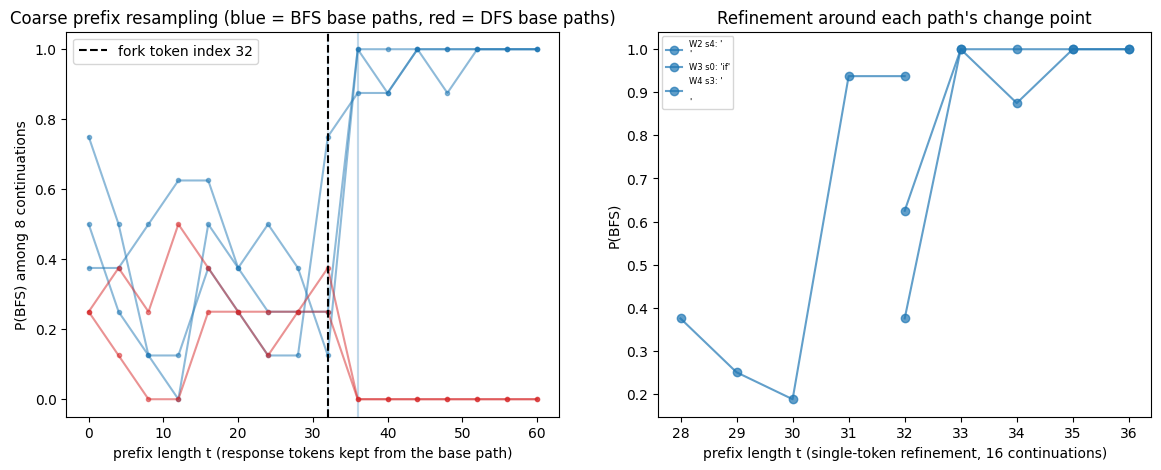

In [17]:
# ---- src/figures_S.py (verbatim; _save(fig, "fork_trajectories") -> plt.show())
MODE_COL = {"bfs": "#1f77b4", "dfs": "#d62728", "bibfs": "#2ca02c", "iddfs": "#9467bd", "astar_gbfs": "#ff7f0e",
            "dijkstra": "#8c564b"}


def fork_figure(fk: dict[str, Any]) -> None:
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    for p in fk["per_path"]:
        col = MODE_COL["bfs"] if p["label"] == "bfs" else MODE_COL["dfs"]
        axs[0].plot(p["t"], p["p_bfs"], color=col, alpha=0.5, marker=".")
        if p["fork_t"] is not None:
            axs[0].axvline(p["fork_t"], color=col, alpha=0.15)
    axs[0].axvline(fk["fork_token_index"], color="k", ls="--", label=f"fork token index {fk['fork_token_index']}")
    axs[0].set_xlabel("prefix length t (response tokens kept from the base path)")
    axs[0].set_ylabel("P(BFS) among 8 continuations")
    axs[0].set_title("Coarse prefix resampling (blue = BFS base paths, red = DFS base paths)")
    axs[0].legend()
    for r in fk.get("refined", []):
        ts = [s["t"] for s in r["series"]]
        ps = [s["p_bfs"] for s in r["series"]]
        axs[1].plot(ts, ps, marker="o", color=MODE_COL["bfs"] if r["label"] == "bfs" else MODE_COL["dfs"], alpha=0.7,
                    label=f"{r['row_id'].split('|')[2]} s{r['row_id'].split('|')[-1]}: '{r['fork_token']}'")
    axs[1].set_xlabel("prefix length t (single-token refinement, 16 continuations)")
    axs[1].set_ylabel("P(BFS)")
    axs[1].legend(fontsize=6)
    axs[1].set_title("Refinement around each path's change point")
    plt.show()


fork_figure(out)

## Results: which token decides the algorithm

The first table is the fork-token table at response index `tf`, the position right after `c*`. For each token there, it gives P(BFS): first on the demo samples and continuations, then as stored in the artifact over 200 natural samples and 3,712 continuations.

The second table checks the replay against the artifact. Seeds, labeller and segmentation code are identical, so the recomputed per-path numbers should match the stored `results/fork.json` values exactly.

In [18]:
stored = meta["stored_fork_results"]
tt_demo = pd.DataFrame([{"token": v["token"], "n": v["n"], "n_bfs": v["n_bfs"], "n_dfs": v["n_dfs"], "p_bfs": v["p_bfs"]}
                        for v in out["token_table"].values()])
tt_full = pd.DataFrame([{"token": v["token"], "n_full": v["n"], "p_bfs_full": v["p_bfs"]}
                        for v in stored["token_table"].values()])
tt = tt_demo.merge(tt_full, on="token", how="outer").sort_values("n", ascending=False, na_position="last")
print(f"fork token index: demo {out['fork_token_index']} | stored {stored['fork_token_index']}")
print(f"B (-> BFS) tokens: demo {out['B_tokens']} | stored {stored['B_tokens']}")
print(f"D (-> DFS) tokens: demo {out['D_tokens']} | stored {stored['D_tokens']}")
print(f"median gap fork -> first algorithm-identifying token: demo {out['gap_fork_to_identifying']['median']} "
      f"| stored {stored['gap_fork_to_identifying']['median']} tokens")
print(tt.to_string(index=False))

# ---- replay vs the stored artifact values (same seeds -> identical numbers expected)
sp = meta["stored_per_path"]
fmt = lambda v, d=4: "-" if v is None else (round(v, d) if isinstance(v, float) else v)  # noqa: E731
chk = pd.DataFrame([{"path": p["row_id"], "label": p["label"],
                     "k_own match": p["k_own"] == sp[p["row_id"]]["k_own"],
                     "p (replay)": fmt(p["cp"]["p_value"]), "p (stored)": fmt(sp[p["row_id"]]["cp"]["p_value"]),
                     "fork_t (replay)": fmt(p["fork_t"]), "fork_t (stored)": fmt(sp[p["row_id"]]["fork_t"]),
                     "rise (replay)": fmt(p["rise"], 3), "rise (stored)": fmt(sp[p["row_id"]]["rise"], 3)}
                    for p in per_path], dtype=object)
print("\n" + chk.to_string(index=False))
sr = {x["row_id"]: x for x in meta["stored_refined"]}
for x in refined:
    s = sr.get(x["row_id"])
    print(f"refined {x['row_id']}: token index {x['fork_token_index']} {x['fork_token']!r} | stored "
          f"{s['fork_token_index'] if s else None} {s['fork_token'] if s else None!r}")
# every data cell also carries the artifact's stored P(BFS); the relabelled continuation texts must agree
n_cells = n_match = 0
for ex in examples:
    cs = [c for c in cont if c["base_row"] == ex["metadata_base_row"] and c["tag"] == ex["metadata_tag"]
          and c["t"] == ex["metadata_t"]]
    if cs:
        n_cells += 1
        n_match += abs(float(ex["predict_p_bfs_continuations"]) - np.mean([c["cls"] == "bfs" for c in cs])) < 1e-4
print(f"\nper-cell P(BFS) recomputed from the continuation texts vs stored: {n_match}/{n_cells} cells match")

fork token index: demo 32 | stored 32
B (-> BFS) tokens: demo ['\n', 'if', 'queue'] | stored ['\n', 'if', 'queue', 'q']
D (-> DFS) tokens: demo ['visited'] | stored ['visited']
median gap fork -> first algorithm-identifying token: demo 129.0 | stored 138.0 tokens
  token   n  n_bfs  n_dfs    p_bfs  n_full  p_bfs_full
visited 297      2    295 0.006734    1409    0.010646
     \n  43     42      1 0.976744     204    0.946078
     if  32     32      0 1.000000     177    0.988636
  queue  20     20      0 1.000000      82    1.000000
      q   1      1      0 1.000000       3    1.000000

           path label k_own match p (replay) p (stored) fork_t (replay) fork_t (stored) rise (replay) rise (stored)
s3|T1|W2|twin|4   bfs        True      0.001      0.001              36              36         0.534         0.534
s3|T1|W3|twin|0   bfs        True      0.001      0.001              36              36         0.722         0.722
s3|T1|W4|twin|3   bfs        True      0.003      0.003  

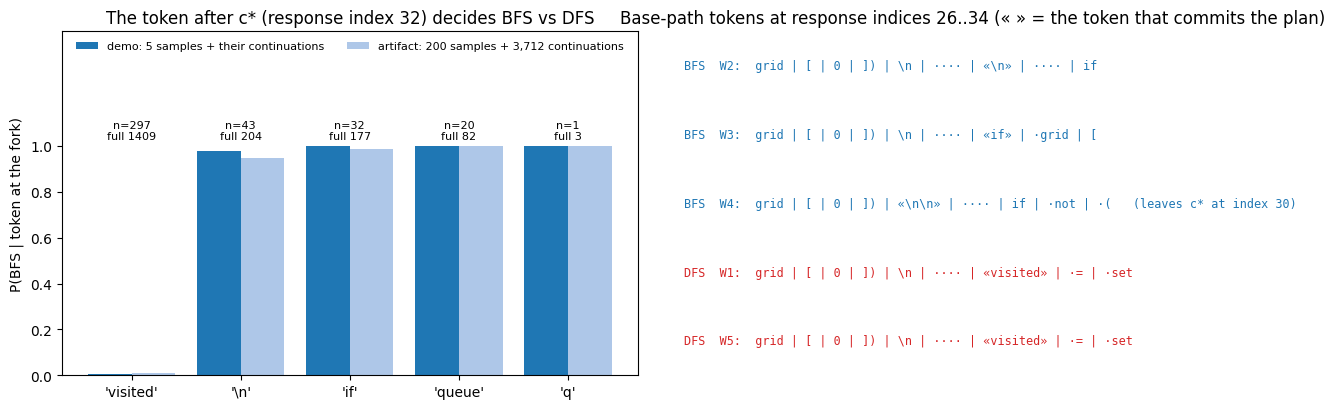

In [19]:
# ---- the fork in one picture: P(BFS | token written at the fork position), demo vs full artifact
plot_tt = tt.dropna(subset=["p_bfs"]).head(8)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(plot_tt))
axs[0].bar(x - 0.2, plot_tt["p_bfs"], 0.4, color="#1f77b4", label="demo: 5 samples + their continuations")
axs[0].bar(x + 0.2, plot_tt["p_bfs_full"].fillna(0), 0.4, color="#aec7e8",
           label="artifact: 200 samples + 3,712 continuations")
for i, (nd, nf) in enumerate(zip(plot_tt["n"], plot_tt["n_full"])):
    axs[0].text(i, 1.03, f"n={int(nd)}" + ("" if pd.isna(nf) else f"\nfull {int(nf)}"), ha="center", fontsize=8)
axs[0].set_xticks(x)
axs[0].set_xticklabels([repr(t) for t in plot_tt["token"]])
axs[0].set_ylim(0, 1.5)
axs[0].set_yticks(np.linspace(0, 1, 6))
axs[0].set_ylabel("P(BFS | token at the fork)")
axs[0].set_title(f"The token after c* (response index {out['fork_token_index']}) decides BFS vs DFS")
axs[0].legend(fontsize=8, loc="upper center", ncol=2, frameon=False)
# right: the base paths' code around the fork, token by token (spaces shown as '·'). « » marks the token that
# commits the plan: the global fork index for paths on c*, else the path's own refined fork index
lo_, hi_ = max(0, out["fork_token_index"] - 6), out["fork_token_index"] + 3
ref_idx = {x["row_id"]: x["fork_token_index"] for x in refined}
for yi, r in enumerate(base):
    ids = response_ids(r)
    on_cstar = ids[:out["fork_token_index"]] == out["cstar_ids"]
    mark = out["fork_token_index"] if on_cstar else ref_idx.get(r["row_id"])
    pieces = [repr(tok.decode([i]))[1:-1].replace(" ", "·") for i in ids[lo_:hi_]]
    if mark is not None and lo_ <= mark < lo_ + len(pieces):
        pieces[mark - lo_] = f"«{pieces[mark - lo_]}»"
    note = "" if on_cstar else f"   (leaves c* at index {F.lcp(ids, out['cstar_ids'])})"
    axs[1].text(0.0, 1 - (yi + 0.5) / len(base),
                f"{r['label'].upper()}  {r['row_id'].split('|')[2]}:  " + " | ".join(pieces) + note,
                fontsize=8.5, family="monospace", color=MODE_COL[r["label"]], va="center")
axs[1].set_axis_off()
axs[1].set_title(f"Base-path tokens at response indices {lo_}..{hi_ - 1} (« » = the token that commits the plan)")
plt.tight_layout()
plt.show()

## Context: what the full artifact found beyond the fork

These numbers come from the artifact's `README.md` and `results/*.json`. They are **not** recomputed here: they need the GPU stages and about 1.6 GB of cached activations.

- **Readout.** A Lasso on layer-29 SAE codes at the fork position predicts the fork log-odds y_v of 120 neutral prompt variants with held-out R² 0.66, against 0.18 for a text-only control (ΔR² 0.49 [0.26, 0.65], p = 0.003). But ridge on the *raw* residual reaches 0.72, and ridge on the same SAE codes ≤ 0.09. So the information is in the residual stream, and the SAE advantage depends on the estimator.
- **Steering at the fork (layer 22).** At matched norm, the logit effect is +4.04 nats for DiM, +1.78 for the SAE clamp, +0.51 for random features and +0.12 for isotropic directions.
  - In generation (N = 50, CRN-paired), the twin baseline gives 13/50 BFS. The SAE clamp gives 30-36, DiM 46-49 and random features 21.
  - Every fork edit collapses correctness: the pass rate falls from 0.84 to 0.16-0.58.
- **DAS.** A rank-1 to rank-4 subspace at the fork moves held-out y by +8.8 to +9.8 nats (random subspaces: about 0). In generation it yields 50/50 BFS programs but 0/50 that pass.
- **Banning the top 5 algorithms** (BFS, DFS, IDDFS, A*, greedy best-first) makes the model *write* BFS more often, not invent something new. BFS rises from 10/50 to 41/50 (McNemar 32 vs 1, p = 7.9e-9), and none of the 50 programs avoids the banned algorithms. Among 1,450 correct programs, 0 were novel.

**Running the full pipeline.** Clone the repository and accept the Gemma licence (`HF_TOKEN`). On one GPU with at least 16 GB, run `method.py --stage s0, gen1, fork, tfgate, variants, select, clamps, das, attrib`, then `label`, `analysis` and `outputs` (see `reproducibility.md`). Raising `N_PATHS_PER_CLASS` beyond the 3 BFS and 2 DFS base paths in this demo needs the full `data/fork_cont.jsonl` of the artifact.